<a href="https://colab.research.google.com/github/Blessy373/Data-Analytics/blob/main/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('/content/titanic.csv')

In [3]:
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


### Programmatic Inspection for Unnecessary Columns
Let's write some code to check for missing values, unique value counts, and overall info to help identify which columns to keep or drop.

In [4]:
# 1. Check for missing values percentage
missing_percent = (df.isnull().sum() / len(df)) * 100

# 2. Check for cardinality (number of unique values)
unique_counts = df.nunique()

# Combine into a summary DataFrame
analysis_df = pd.DataFrame({
    'Missing %': missing_percent,
    'Unique Values': unique_counts,
    'Data Type': df.dtypes
})

display(analysis_df)

,Missing %,Unique Values,Data Type
PassengerId,0.000000,891,int64
Survived,0.000000,2,int64
Pclass,0.000000,3,int64
Name,0.000000,891,object
Sex,0.000000,2,object
Age,19.865320,88,float64
SibSp,0.000000,7,int64
Parch,0.000000,7,int64
Ticket,0.000000,681,object
Fare,0.000000,248,float64


In [29]:
df['Embarked'].unique()

array(['S', 'C', 'Q'], dtype=object)

### What this analysis tells us:
- **`PassengerId`**: Has 891 unique values (one for every row). This is just an index and is completely unnecessary for machine learning.
- **`Cabin`**: Has over 77% missing values. It's often dropped because there is too little data to learn from, or it must be heavily processed.
- **`Ticket`**: Has 681 unique values. It represents complex ticket codes that are difficult to use without complex text extraction, making it a common candidate for removal.
- **`Name`**: Has 891 unique values, but can be used to extract titles (Mr, Mrs, etc.) before being dropped.

### Analyzing 'Sex' and 'Fare' in relation to Survival

/tmp/ipykernel_889/2693480072.py:8: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0], ci=None, palette='pastel')
/tmp/ipykernel_889/2693480072.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0], ci=None, palette='pastel')
/tmp/ipykernel_889/2693480072.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Survived', y='Fare', data=df, ax=axes[1], palette='pastel')
/tmp/ipykernel_889/2693480072.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xtickl

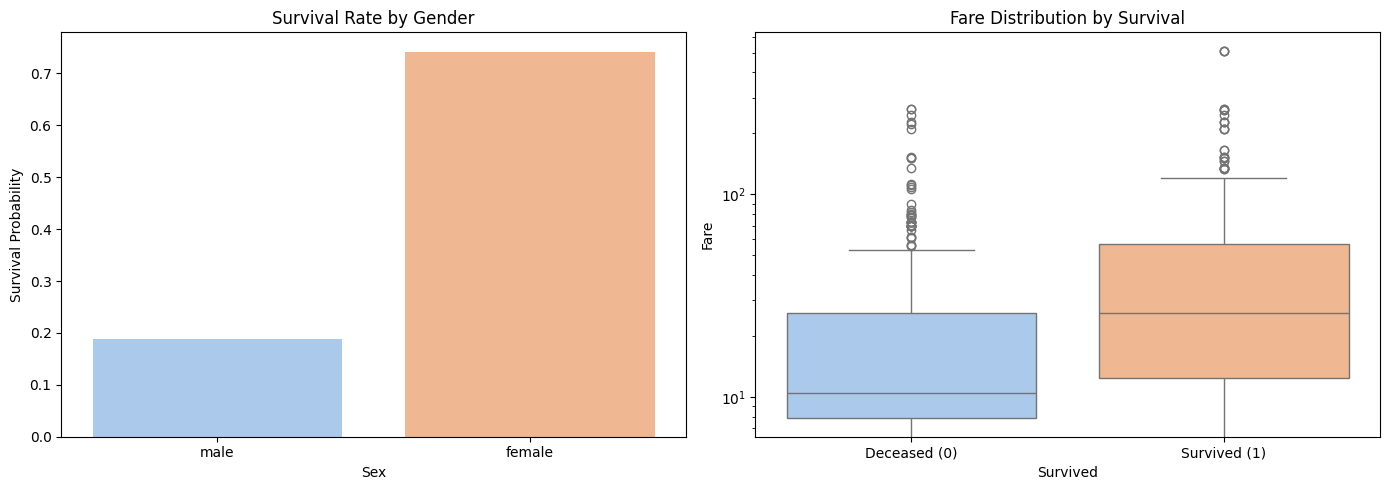

--- Gender Survival Breakdown ---
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

--- Average Fare paid by Survival status ---
Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the visualization figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Survival Rate by Sex
sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0], ci=None, palette='pastel')
axes[0].set_title('Survival Rate by Gender')
axes[0].set_ylabel('Survival Probability')

# 2. Distribution of Fare for Survivors vs Non-Survivors
sns.boxplot(x='Survived', y='Fare', data=df, ax=axes[1], palette='pastel')
axes[1].set_title('Fare Distribution by Survival')
axes[1].set_yscale('log') # Log scale because some fares are extremely high
axes[1].set_xticklabels(['Deceased (0)', 'Survived (1)'])

plt.tight_layout()
plt.show()

# Programmatic summary
print("--- Gender Survival Breakdown ---")
print(df.groupby('Sex')['Survived'].mean())

print("\n--- Average Fare paid by Survival status ---")
print(df.groupby('Survived')['Fare'].mean())

In [10]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [14]:
df.drop(['PassengerId','Name','Cabin','Ticket'],axis=1,inplace=True)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [16]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


#Filling null values

In [18]:
df['Age'].median()

28.0

In [21]:
df['Age']=df['Age'].fillna(df['Age'].median())

In [26]:
df.fillna({'Embarked':df['Embarked'].mode()[0]},inplace=True)

In [27]:
df.isna().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


#Encoding:


In [30]:
from sklearn.preprocessing import OneHotEncoder
data=OneHotEncoder(drop='first',sparse_output=False,dtype=int).fit_transform(df[['Sex','Embarked']])

In [31]:
data

array([[1, 0, 1],
       [0, 0, 0],
       [0, 0, 1],
       ...,
       [0, 0, 1],
       [1, 0, 0],
       [1, 1, 0]], shape=(891, 3))

In [35]:
df_en=pd.DataFrame(data,columns=['sex_male','embarked_c','embarked_Q'])

In [36]:
df=pd.concat([df,df_en],axis=1)

In [40]:
df.drop(['Sex','Embarked'],axis=1,inplace=True)

In [41]:
df

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,sex_male,embarked_c,embarked_Q
0,0,3,22.0,1,0,7.2500,1,0,1,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,1,0,1,1,0,1
887,1,1,19.0,0,0,30.0000,0,0,1,0,0,1
888,0,3,28.0,1,2,23.4500,0,0,1,0,0,1
889,1,1,26.0,0,0,30.0000,1,0,0,1,0,0


Test and train split

In [42]:
from sklearn.model_selection import train_test_split
x=df.drop('Survived',axis=1)
y=df['Survived']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=4)

Scalling

In [43]:
from sklearn.preprocessing import MinMaxScaler
mm=MinMaxScaler()
mm.fit_transform(x_train)
mm.transform(x_test)

array([[1.        , 0.23347575, 0.        , ..., 1.        , 0.        ,
        1.        ],
       [1.        , 0.24604172, 0.        , ..., 1.        , 0.        ,
        1.        ],
       [1.        , 0.34656949, 0.        , ..., 0.        , 1.        ,
        0.        ],
       ...,
       [1.        , 0.63558683, 0.        , ..., 1.        , 0.        ,
        1.        ],
       [0.        , 0.2963056 , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.5       , 0.2963056 , 0.        , ..., 1.        , 0.        ,
        1.        ]], shape=(179, 11))

In [44]:
from sklearn.tree import DecisionTreeClassifier
D=DecisionTreeClassifier()
D.fit(x_train,y_train)

DecisionTreeClassifier()

In [48]:
D.score(x_train,y_train)

0.9817415730337079

In [50]:
D.score(x_test,y_test)

0.8212290502793296